In [1]:
import cv2
import matplotlib.pyplot as plt
import numpy as np
from sklearn.cluster import KMeans

In [12]:

image_path = "C:/Users/moham/Downloads/testat/kounde.png"
image = cv2.imread(image_path)
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

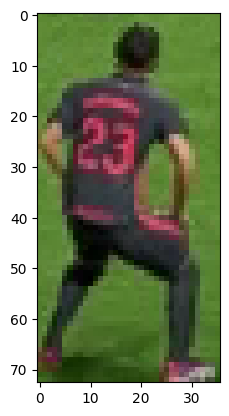

In [13]:
plt.imshow(image)
plt.show()

# take the top half of the image

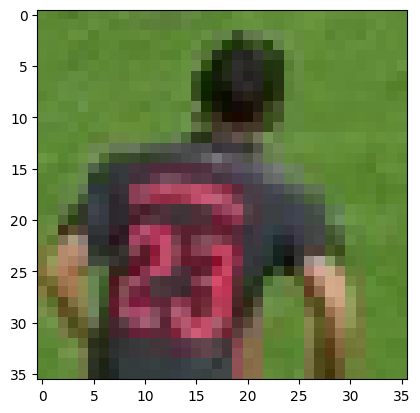

In [14]:
top_half_image=  image[0: int(image.shape[0]/2), :]

plt.imshow(top_half_image)
plt.show()

In [15]:
avg_rgb = np.mean(top_half_image, axis=(0,1))
avg = np.mean([avg_rgb[0], avg_rgb[2]])
avg

np.float64(76.32484567901234)

# Cluster the image into two clusters

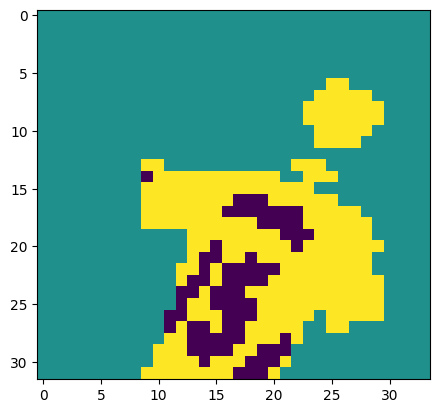

In [160]:
# Reshape the image into 2d array
image_2d = top_half_image.reshape(-1, 3)

# perform k-means clustering with 2 clusters
kmeans = KMeans(n_clusters=3, random_state=0)
kmeans.fit(image_2d)

# get the cluster labels
labels = kmeans.labels_

# reshape the labels into the orginal image shape
clustered_image = labels.reshape(top_half_image.shape[0], top_half_image.shape[1])

# Display the clustered image
plt.imshow(clustered_image)
plt.show()

In [161]:
corner_clusters = [clustered_image[0, 0], clustered_image[0, -1], clustered_image[-1, 0], clustered_image[-1, -1]]
non_player_cluster = max(set(corner_clusters), key=corner_clusters.count)
print(non_player_cluster)



1


In [162]:
# player_cluster = 1-non_player_cluster
# print(player_cluster)
# Find the cluster with the maximum number of assignees that is not the non_player_cluster
assignees_count = np.bincount(labels)
assignees_count[non_player_cluster] = -1  # Exclude the non_player_cluster
player_cluster = np.argmax(assignees_count)
print(player_cluster)

2


[63.10162602 55.03658537 53.70325203]


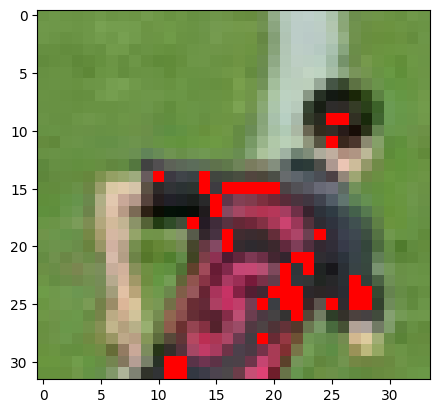

In [163]:
playerColor = kmeans.cluster_centers_[player_cluster]
print(playerColor)
# Create a mask for the player color
player_mask = cv2.inRange(top_half_image, playerColor - 10, playerColor + 10)

# Create an output image to display the player color
output_image = top_half_image.copy()
output_image[player_mask > 0] = [255, 0, 0]  # Color the player pixels in red

# Display the output image
plt.imshow(output_image)
plt.show()

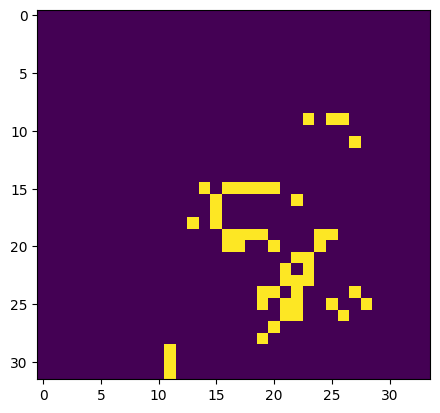

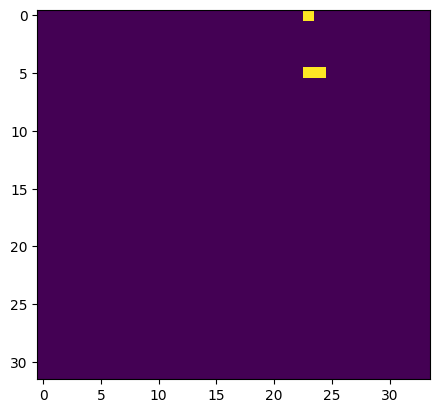

49 3
The team of the image is: Barca


In [164]:
# # barca colors
# # [63.51434426, 46.79918033, 47.5307377 ]
# # [75.74074074, 55.53872054, 58.18518519]
# # array([54.1350211 , 52.38396624, 48.40084388])
# # [65.2421875  49.83203125 49.16796875]

# # barca color range
# lower_barca_color = np.array([50 , 40, 42])
# upper_barca_color = np.array([80, 60, 62])


# # madrid colors 
# # [222.96164384 223.42739726 222.54246575]
# # [212.2674772  215.71732523 216.12765957]
# # [193.12844037 198.15902141 193.81651376]
# # [201.75535168 206.36697248 207.44648318]

# lower_madrid_color = np.array([190, 190, 190])
# upper_madrid_color = np.array([230, 230, 230])

# # Create a mask for the barca colors
# barca_mask = cv2.inRange(top_half_image, lower_barca_color, upper_barca_color)

# # Create a mask for the madrid colors
# madrid_mask = cv2.inRange(top_half_image, lower_madrid_color, upper_madrid_color)

# # Assign team based on the masks
# team_assignmentB = np.zeros(clustered_image.shape, dtype=np.uint8)
# team_assignmentM = np.zeros(clustered_image.shape, dtype=np.uint8)
# team_assignmentB[barca_mask > 0] = 1  # Barca team
# team_assignmentM[madrid_mask > 0] = 2  # Madrid team

# plt.imshow(barca_mask, cmap='viridis')
# plt.show()
# plt.imshow(team_assignmentM, cmap='viridis')
# plt.show()
# # Determine the team with the maximum in-range color
# barca_count = np.sum(barca_mask > 0)
# madrid_count = np.sum(madrid_mask > 0)
# print(barca_count, madrid_count)

# if barca_count > madrid_count:
#     team = "Barca"
# else:
#     team = "Madrid"

# print(f"The team of the image is: {team}")

Average color for the cluster with max assignees: [82.72647059 61.37647059 62.74411765]


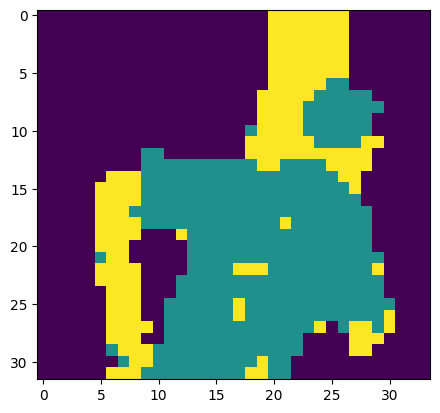

In [166]:
# import cv2
# import matplotlib.pyplot as plt
# import numpy as np
# from sklearn.cluster import KMeans

# # Load the image
# image_path = "C:/Users/DELL/Pictures/Screenshots/barca2.png"
# image = cv2.imread(image_path)
# image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# # Take the top half of the image
# top_half_image = image[0: int(image.shape[0] / 2), :]

# # Define the green color range in HSV
# lower_green = np.array([35, 100, 100])
# upper_green = np.array([85, 255, 255])

# # Convert the image to HSV
# hsv_image = cv2.cvtColor(top_half_image, cv2.COLOR_RGB2HSV)

# # Create a mask for the green color
# mask = cv2.inRange(hsv_image, lower_green, upper_green)

# # Invert the mask to get the non-green pixels
# mask_inv = cv2.bitwise_not(mask)

# # Extract the non-green pixels
# non_green_pixels = top_half_image[mask_inv == 255]

# # Perform k-means clustering with 2 clusters on non-green pixels
# kmeans = KMeans(n_clusters=2, random_state=0)
# kmeans.fit(non_green_pixels)

# # Get the cluster labels for non-green pixels
# labels = kmeans.labels_

# # Create an empty array for the clustered image
# clustered_image = np.zeros((top_half_image.shape[0], top_half_image.shape[1]), dtype=np.uint8)

# # Assign the cluster labels to the non-green pixels in the clustered image
# clustered_image[mask_inv == 255] = labels + 1  # Adding 1 to differentiate from the green background


# # Find the cluster with the maximum number of assignees
# max_assignees_cluster = np.argmax(np.bincount(labels))


# # Print the average color for the cluster with the maximum number of assignees
# print(f"Average color for the cluster with max assignees: {kmeans.cluster_centers_[max_assignees_cluster]}")

# # Display the clustered image
# plt.imshow(clustered_image, cmap='viridis')
# plt.show()